# データと経済統計　課題：オープンデータを用いた統計的仮説検定

**テーマ：東京の年平均気温は、この数十年で上がったと言えるか？**

| 項目 | 内容 |
|---|---|
| 使用データ | 気象庁「過去の気象データ検索」 東京（地点番号 47662）の日平均気温の月平均値・年の値 |
| 検定手法 | 母平均の差の検定（2標本・Welch の t 検定）、右側の片側検定 |
| 有意水準 | α = 0.05 |

## 1. 問題

気象庁が公開している東京の気象観測データ（オープンデータ）を使う。

> 東京の **1955〜1984年（前期30年）** と **1985〜2014年（後期30年）** の年平均気温を比べる。
> 後期の年平均気温の母平均は、前期より **高い** と言えるか。有意水準 5% で検定せよ。

**期間を 2014年で区切った理由**
東京の観測所は **2014年12月2日に大手町から北の丸公園へ移転** した。気象庁の表でも、この前後は「データが均質でない（そのまま比較できない）」ことを示す赤線が引かれている。
そのため、本検定では移転前のデータだけを使い、同じ観測所の 30年 と 30年 を比べる。
（参考として、移転後を含めた比較も最後に示す。）

## 2. 使用したオープンデータ

- **出典**：気象庁「過去の気象データ検索」 › 観測開始からの毎月の値 › 東京（東京都） › 日平均気温の月平均値（℃）
- **URL**：https://www.data.jma.go.jp/stats/etrn/view/monthly_s3.php?prec_no=44&block_no=47662&year=&month=&day=&view=a1
- **取得日**：2026年11月12日
- **提出ファイル**：`tokyo_monthly_mean_temp_jma.csv`（上のページの表を CSV に変換したもの）
  - 列：`年`, `1月`〜`12月`, `年の値`, `品質記号`
  - 気象庁の表では、値の後ろに `)`（準正常値）や `]`（資料不足値）などの記号が付くことがある。数値と記号を分け、記号は `品質記号` 列に残した。
  - 本検定で使う 1955〜2014年 の `年の値` には、品質記号の付いた値は **ない**。

## 3. データの読み込み

Google Colab で実行するときは、提出した CSV ファイルを左の「ファイル」欄にアップロードしてから実行する。
ファイルが見つからない場合は、アップロード画面が開く。

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

CSV = "tokyo_monthly_mean_temp_jma.csv"

if not os.path.exists(CSV):
    try:
        from google.colab import files   # Colab のときだけ
        print(f"{CSV} をアップロードしてください")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"{CSV} が見つかりません。ノートブックと同じフォルダに置いてください。")

df = pd.read_csv(CSV, encoding="utf-8-sig")
print(df.shape)
df.tail()

(152, 15)


,年,1月,2月,3月,4月,5月,6月,7月,8月,9月,10月,11月,12月,年の値,品質記号
147,2022,4.9,5.2,10.9,15.3,18.8,23.0,27.4,27.5,24.4,17.2,14.5,7.5,16.4,NaN
148,2023,5.7,7.3,12.9,16.3,19.0,23.2,28.7,29.2,26.7,18.9,14.4,9.4,17.6,NaN
149,2024,7.1,8.0,9.6,17.1,20.0,23.1,28.7,29.0,26.6,20.6,13.7,8.1,17.6,NaN
150,2025,6.6,6.5,10.7,15.6,19.2,24.7,28.4,29.6,26.5,18.5,12.8,8.4,17.3,NaN
151,2026,6.1,8.0,11.0,16.6,20.4,21.5,27.2,26.7,22.7,19.9,13.9,NaN,18.0,11月:] 年の値:]


（任意）気象庁のサイトから直接取得して、提出した CSV と同じ値になっているか確認するコード。
実行しなくても以降の分析はできる。

In [2]:
CHECK_WITH_JMA = False   # True にすると気象庁のページから直接読み込んで照合する

if CHECK_WITH_JMA:
    url = ("https://www.data.jma.go.jp/stats/etrn/view/monthly_s3.php"
           "?prec_no=44&block_no=47662&year=&month=&day=&view=a1")
    web = pd.read_html(url)[0]
    web.columns = ["年"] + [f"{m}月" for m in range(1, 13)] + ["年の値"]
    web = web[web["年"].astype(str).str.fullmatch(r"\d{4}")].copy()
    web["年"] = web["年"].astype(int)
    web["年の値"] = pd.to_numeric(web["年の値"].astype(str).str.extract(r"(-?\d+\.?\d*)")[0], errors="coerce")
    m = df.merge(web[["年", "年の値"]], on="年", suffixes=("_csv", "_web"))
    m = m[m["年"].between(1955, 2014)]
    print("1955〜2014年で値が違う年の数:", (m["年の値_csv"] != m["年の値_web"]).sum())

## 4. 2つの標本を作る

In [3]:
early = df[df["年"].between(1955, 1984)].set_index("年")["年の値"]   # 前期
late  = df[df["年"].between(1985, 2014)].set_index("年")["年の値"]   # 後期

# 品質記号の付いた値が含まれていないか確認
used = df[df["年"].between(1955, 2014)]
print("品質記号の付いた年:", used.loc[used["品質記号"].notna(), "年"].tolist())
print("欠損値の数:", early.isna().sum() + late.isna().sum())

summary = pd.DataFrame({
    "標本サイズ n": [early.size, late.size],
    "標本平均 (℃)": [early.mean(), late.mean()],
    "標本標準偏差 s (℃)": [early.std(ddof=1), late.std(ddof=1)],
    "最小 (℃)": [early.min(), late.min()],
    "最大 (℃)": [early.max(), late.max()],
}, index=["前期 1955-1984", "後期 1985-2014"]).round(3)
summary

品質記号の付いた年: []
欠損値の数: 0


,標本サイズ n,標本平均 (℃),標本標準偏差 s (℃),最小 (℃),最大 (℃)
前期 1955-1984,30,15.440,0.472,14.6,16.9
後期 1985-2014,30,16.427,0.526,15.2,17.3


## 5. 可視化

（Colab で日本語が文字化けしないよう、グラフのラベルは英語にしている。）

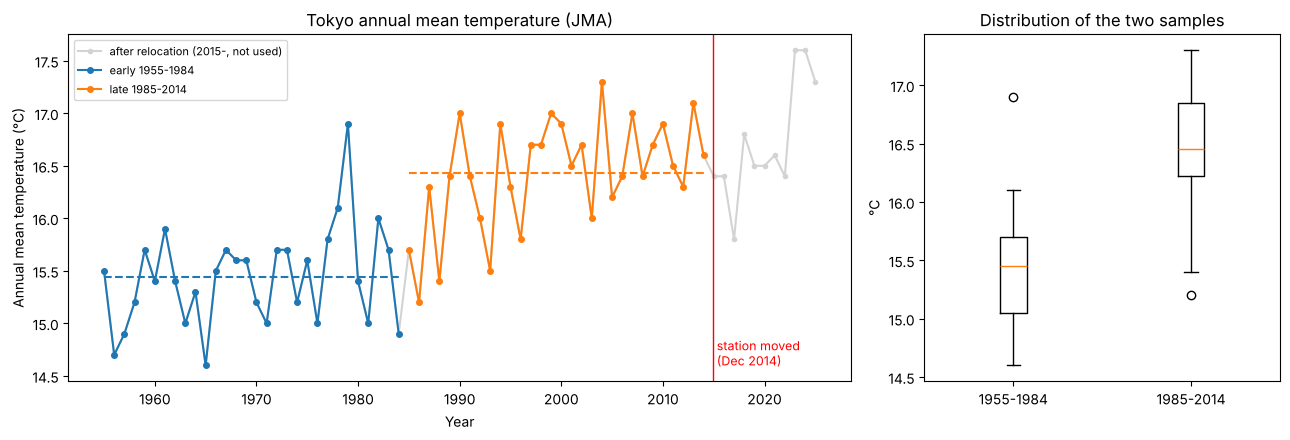

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})

ax = axes[0]
all_years = df[df["年"].between(1955, 2025)].set_index("年")["年の値"]
ax.plot(all_years.index, all_years.values, color="lightgray", marker="o", ms=3, label="after relocation (2015-, not used)")
ax.plot(early.index, early.values, marker="o", ms=4, label="early 1955-1984")
ax.plot(late.index, late.values, marker="o", ms=4, label="late 1985-2014")
ax.hlines(early.mean(), 1955, 1984, colors="C0", linestyles="--")
ax.hlines(late.mean(), 1985, 2014, colors="C1", linestyles="--")
ax.axvline(2014.9, color="red", lw=1)
ax.text(2015.3, all_years.min(), "station moved\n(Dec 2014)", color="red", fontsize=9)
ax.set_xlabel("Year"); ax.set_ylabel("Annual mean temperature (°C)")
ax.set_title("Tokyo annual mean temperature (JMA)")
ax.legend(fontsize=8, loc="upper left")

ax = axes[1]
ax.boxplot([early.values, late.values])
ax.set_xticks([1, 2], ["1955-1984", "1985-2014"])
ax.set_ylabel("°C"); ax.set_title("Distribution of the two samples")

plt.tight_layout(); plt.show()

グラフを見ると、後期の方が全体的に高い。ただし、見た目の差が「たまたま（標本のばらつき）」で説明できる程度なのかを、検定で確かめる。

## 6. 仮説の設定

前期の年平均気温の母平均を $\mu_1$、後期の母平均を $\mu_2$ とする。

- **帰無仮説 $H_0$**：$\mu_2 - \mu_1 = 0$（後期と前期で平均気温に差はない）
- **対立仮説 $H_1$**：$\mu_2 - \mu_1 > 0$（後期の方が平均気温が高い） → **右側の片側検定**
- **有意水準**：$\alpha = 0.05$

**検定統計量**（講義資料「母平均の差の検定」の $T = \dfrac{\bar{x}_1 - \bar{x}_2}{SE}$ に、後期 − 前期 の向きで当てはめる）

$$
SE = \sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}, \qquad
T = \frac{\bar{x}_2 - \bar{x}_1}{SE}
$$

2つの期間で分散が等しいとは限らないので、分散が等しいことを仮定しない **Welch の t 検定** を使う。
自由度は Welch–Satterthwaite の式で求める。

$$
\nu = \frac{\left(\dfrac{s_1^2}{n_1} + \dfrac{s_2^2}{n_2}\right)^2}
{\dfrac{(s_1^2/n_1)^2}{n_1-1} + \dfrac{(s_2^2/n_2)^2}{n_2-1}}
$$

## 7. 講義の式で計算する

In [5]:
alpha = 0.05
n1, n2 = early.size, late.size
x1, x2 = early.mean(), late.mean()
s1, s2 = early.std(ddof=1), late.std(ddof=1)

diff = x2 - x1                                   # 標本平均の差
SE = np.sqrt(s1**2 / n1 + s2**2 / n2)            # 標準誤差
T = diff / SE                                    # 検定統計量
nu = (s1**2/n1 + s2**2/n2)**2 / ((s1**2/n1)**2/(n1-1) + (s2**2/n2)**2/(n2-1))   # Welch の自由度

t_crit = stats.t.ppf(1 - alpha, nu)              # 右側 5% の棄却限界値
p_value = stats.t.sf(T, nu)                      # 右側の p 値 = P(t >= T)

# 信頼区間
t975 = stats.t.ppf(0.975, nu)
ci95 = (diff - t975 * SE, diff + t975 * SE)      # 差の 95% 信頼区間（両側）
lower95 = diff - t_crit * SE                     # 片側 95% 信頼区間の下限（片側検定と対応）

print(f"標本平均の差  x̄2 - x̄1 = {diff:.3f} ℃")
print(f"標準誤差      SE      = {SE:.4f}")
print(f"検定統計量    T       = {T:.3f}")
print(f"自由度        ν       = {nu:.2f}")
print(f"棄却限界値    t(0.95, ν) = {t_crit:.3f}")
print(f"p 値（右側）           = {p_value:.2e}")
print(f"差の95%信頼区間（両側）= [{ci95[0]:.3f}, {ci95[1]:.3f}] ℃")
print(f"片側95%信頼区間        = [{lower95:.3f}, ∞) ℃")

標本平均の差  x̄2 - x̄1 = 0.987 ℃
標準誤差      SE      = 0.1290
検定統計量    T       = 7.650
自由度        ν       = 57.33
棄却限界値    t(0.95, ν) = 1.672
p 値（右側）           = 1.27e-10
差の95%信頼区間（両側）= [0.728, 1.245] ℃
片側95%信頼区間        = [0.771, ∞) ℃


## 8. ライブラリ（SciPy）で確認する

手計算の結果と、`scipy.stats.ttest_ind`（`equal_var=False` で Welch の t 検定）の結果が一致するか確認する。

In [6]:
res = stats.ttest_ind(late, early, equal_var=False, alternative="greater")
print(f"SciPy: t = {res.statistic:.3f}, p = {res.pvalue:.2e}")
print("手計算と一致:", np.isclose(res.statistic, T) and np.isclose(res.pvalue, p_value))

SciPy: t = 7.650, p = 1.27e-10
手計算と一致: True


## 9. 有意差の判定

講義で扱った3つの方法で判定する。

In [7]:
judge = pd.DataFrame({
    "判定方法": ["T値と棄却限界値", "p値と有意水準", "信頼区間"],
    "比較": [f"T = {T:.2f}  vs  棄却限界値 = {t_crit:.2f}",
             f"p = {p_value:.1e}  vs  α = {alpha}",
             f"片側95%CI = [{lower95:.2f}, ∞)、両側95%CI = [{ci95[0]:.2f}, {ci95[1]:.2f}]"],
    "結果": ["T ≥ 棄却限界値 → H0 を棄却" if T >= t_crit else "H0 を棄却できない",
             "p ≤ α → H0 を棄却" if p_value <= alpha else "H0 を棄却できない",
             "0 を含まない → H0 を棄却" if lower95 > 0 else "0 を含む → H0 を棄却できない"],
})
judge

,判定方法,比較,結果
0,T値と棄却限界値,T = 7.65 vs 棄却限界値 = 1.67,T ≥ 棄却限界値 → H0 を棄却
1,p値と有意水準,p = 1.3e-10 vs α = 0.05,p ≤ α → H0 を棄却
2,信頼区間,"片側95%CI = [0.77, ∞)、両側95%CI = [0.73, 1.24]",0 を含まない → H0 を棄却


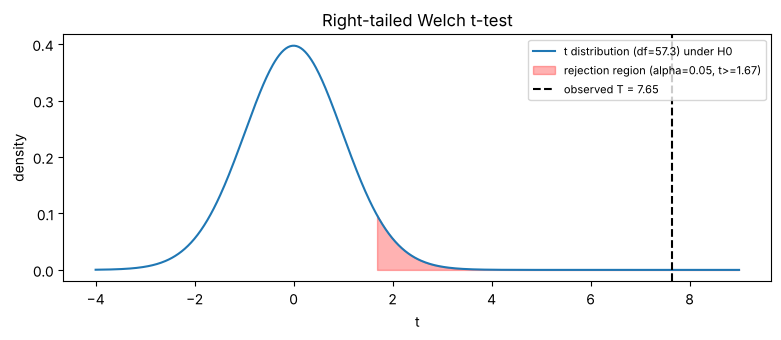

In [8]:
# t 分布上で T の位置と棄却域を図示
x = np.linspace(-4, max(9, T + 1), 600)
plt.figure(figsize=(8, 3.5))
plt.plot(x, stats.t.pdf(x, nu), label=f"t distribution (df={nu:.1f}) under H0")
xr = x[x >= t_crit]
plt.fill_between(xr, stats.t.pdf(xr, nu), color="red", alpha=0.3, label=f"rejection region (alpha=0.05, t>={t_crit:.2f})")
plt.axvline(T, color="black", ls="--", label=f"observed T = {T:.2f}")
plt.xlabel("t"); plt.ylabel("density"); plt.legend(fontsize=8)
plt.title("Right-tailed Welch t-test")
plt.tight_layout(); plt.show()

## 10. 結論

- 前期（1955〜1984年）の年平均気温は **約15.44℃**、後期（1985〜2014年）は **約16.43℃** で、差は **約0.99℃**。
- 検定統計量は **T ≈ 7.65**。右側 5% の棄却限界値 **約1.67** を大きく上回る。p 値は **約 1.3×10⁻¹⁰** で、α = 0.05 よりはるかに小さい。
- 差の 95% 信頼区間はおよそ **[0.73, 1.24]℃** で、0 をまたがない。

→ 3つの方法すべてで **帰無仮説を棄却し、対立仮説を採択** する。
**「1985〜2014年の東京の年平均気温は、1955〜1984年より高い」と、有意水準 5% で言える。** 上昇幅は 0.7〜1.3℃ 程度と推定される。

（上の数値は 2026年11月12日に取得したデータで計算したもの。セルを実行すると同じ値が出る。）

## 11. 考察と注意点

検定の前提（講義資料「統計的仮説検定と手順（前提）」）に照らすと、次の点に注意が必要である。

1. **ランダムサンプリングではない**
   各期間の 30年分を「母集団から無作為に取り出した標本」とみなしている。実際の気温は年ごとに独立ではなく、ゆるやかな上昇傾向（トレンド）や、エルニーニョなどによる数年単位の変動がある。そのため、独立性を仮定した t 検定の p 値は、実際より小さく出ている可能性がある。ただし今回は T が棄却限界値の4倍以上あるため、結論が変わるほどの影響は考えにくい。

2. **「なぜ上がったか」までは分からない**
   この検定で言えるのは「後期の方が平均気温が高い」ということだけである。地球温暖化と、ヒートアイランド現象（都市化）の影響を区別することはできない。気象庁も、東京などの大都市の気温上昇には都市化の影響が大きいと説明している。

3. **観測所の移転**
   2014年12月の移転の前後は値をそのまま比べられないため、移転前のデータだけを使った。移転後のデータを混ぜると、気温の変化と、観測場所が変わったことによる差が区別できなくなる。

4. **正規性**
   各標本は n = 30 で、中心極限定理により標本平均の分布は正規分布に近いとみなせる（講義資料：n ≥ 30 で t 推定）。念のため、Shapiro–Wilk 検定で各標本の正規性も確認しておく（下のセル）。

In [9]:
for name, s in [("前期", early), ("後期", late)]:
    w, p = stats.shapiro(s)
    print(f"{name}: Shapiro-Wilk W = {w:.3f}, p = {p:.3f}  ->",
          "正規性は否定されない" if p > 0.05 else "正規性が否定される")

前期: Shapiro-Wilk W = 0.948, p = 0.154  -> 正規性は否定されない
後期: Shapiro-Wilk W = 0.952, p = 0.195  -> 正規性は否定されない


## 12. 参考：移転後のデータを含めた比較

参考として、直近の 30年（1996〜2025年）と、その前の 30年（1966〜1995年）も比べる。
**2015年以降は観測所移転後の値なので、厳密には比較できない**（気象庁の赤線の前後）。結果は参考にとどめる。

In [10]:
a = df[df["年"].between(1966, 1995)]["年の値"]
b = df[df["年"].between(1996, 2025)]["年の値"]
r = stats.ttest_ind(b, a, equal_var=False, alternative="greater")
print(f"1966-1995 平均 = {a.mean():.2f} ℃,  1996-2025 平均 = {b.mean():.2f} ℃,  差 = {b.mean()-a.mean():.2f} ℃")
print(f"Welch t = {r.statistic:.2f}, p = {r.pvalue:.2e}")

1966-1995 平均 = 15.76 ℃,  1996-2025 平均 = 16.65 ℃,  差 = 0.90 ℃
Welch t = 6.71, p = 5.73e-09


---
**出典**：気象庁「過去の気象データ検索」（https://www.data.jma.go.jp/stats/etrn/index.php ）。
気象庁ホームページのコンテンツは「気象庁ホームページ利用規約」（政府標準利用規約 第2.0版に準拠）に基づき、出典を記載すれば利用できる。